In [3]:
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm.auto import tqdm

In [7]:
os.listdir()

['0000000938.npz',
 '0000000203.npz',
 '0000000208.npz',
 '0000002810.npz',
 '0000000149.npz',
 '0000002702.npz',
 '0000000827.npz',
 '0000002720.npz',
 '0000002910.npz',
 '0000000830.npz',
 '0000001727.npz',
 '0000003712.npz',
 '0000000080.npz',
 '0000003824.npz',
 '0000000409.npz',
 '0000000257.npz',
 '0000002371.npz',
 '0000000835.npz',
 '0000000253.npz',
 '0000002690.npz',
 '0000000145.npz',
 '0000000311.npz',
 '0000001024.npz',
 '0000000414.npz',
 '0000001321.npz',
 '0000003316.npz',
 '0000002618.npz',
 '0000000357.npz',
 '0000001225.npz',
 '0000001439.npz',
 '0000000142.npz',
 '0000003652.npz',
 '0000000298.npz',
 '0000002025.npz',
 '0000000199.npz',
 '0000000824.npz',
 '0000002904.npz',
 '0000001227.npz',
 '0000002650.npz',
 '0000001157.npz',
 '0000000470.npz',
 '0000002911.npz',
 '0000002300.npz',
 '0000001199.npz',
 '0000003693.npz',
 '0000003278.npz',
 '0000003207.npz',
 '0000000733.npz',
 '0000002991.npz',
 '0000002542.npz',
 '0000002238.npz',
 '0000000678.npz',
 '0000003547

In [8]:
path = os.path.join("..","rpg_vid2e","data","upsample_input_smaller_events","seq0")
events = sorted([os.path.join(path, file) for file in os.listdir(path)])

os.listdir(path)

['0000000938.npz',
 '0000000203.npz',
 '0000000208.npz',
 '0000002810.npz',
 '0000000149.npz',
 '0000002702.npz',
 '0000000827.npz',
 '0000002720.npz',
 '0000002910.npz',
 '0000000830.npz',
 '0000001727.npz',
 '0000003712.npz',
 '0000000080.npz',
 '0000003824.npz',
 '0000000409.npz',
 '0000000257.npz',
 '0000002371.npz',
 '0000000835.npz',
 '0000000253.npz',
 '0000002690.npz',
 '0000000145.npz',
 '0000000311.npz',
 '0000001024.npz',
 '0000000414.npz',
 '0000001321.npz',
 '0000003316.npz',
 '0000002618.npz',
 '0000000357.npz',
 '0000001225.npz',
 '0000001439.npz',
 '0000000142.npz',
 '0000003652.npz',
 '0000000298.npz',
 '0000002025.npz',
 '0000000199.npz',
 '0000000824.npz',
 '0000002904.npz',
 '0000001227.npz',
 '0000002650.npz',
 '0000001157.npz',
 '0000000470.npz',
 '0000002911.npz',
 '0000002300.npz',
 '0000001199.npz',
 '0000003693.npz',
 '0000003278.npz',
 '0000003207.npz',
 '0000000733.npz',
 '0000002991.npz',
 '0000002542.npz',
 '0000002238.npz',
 '0000000678.npz',
 '0000003547

In [21]:
data = np.load(events[1])

width = 320
height = 240

frames = []

data["t"]

array([4201673, 4207792, 4462044, 4514078, 4520113, 4564704, 4583584,
       4707298, 4727395, 4757157, 4790531, 4824701, 4908513, 4944147,
       4980719, 5043373, 5117202, 5152651, 5154485, 5177591, 5241719,
       5264042, 5264926, 5291749, 5348768, 5360225, 5405514, 5432146,
       5467037, 5474702, 5531837, 5587757, 5620859, 5628480, 5668819,
       5675597, 5686301, 5689477, 5702232, 5752185, 5775579, 5783000,
       5792175, 5798204, 5871211, 5876488, 5876488, 5878487, 5883186,
       5901300, 5927917, 5957505, 5985759, 5985901, 6009498, 6010599,
       6015475, 6062091, 6062262, 6071843, 6103692, 6106395, 6117249,
       6118764, 6119692, 6122003, 6133349, 6140655, 6143100, 6161449,
       6169768, 6170606, 6183917, 6203964, 6214344, 6215751])

array([4035952, 4049917])

In [11]:
import numpy as np
from tqdm import tqdm

# Input: ts, xs, ys, polarity, height, width
def generate_event_frames(ts, xs, ys, polarity, height, width, accumulation_time=1e3):
    """
    Creates frames from event data.
    
    Parameters:
        ts: array of timestamps (in microseconds or similar units)
        xs, ys: coordinates of events
        polarity: +/-1 for ON/OFF events
        height, width: size of output frame
        accumulation_time: duration per frame in same unit as ts (e.g., microseconds)
    
    Returns:
        frames: list of RGB frames (height, width, 3)
    """
    frames = []
    t_start = ts.min()
    t_end = ts.max()
    
    # Create bins from start to end in steps of accumulation_time
    time_bins = np.arange(t_start, t_end, accumulation_time)
    
    for t0 in tqdm(time_bins):
        t1 = t0 + accumulation_time
        mask = (ts >= t0) & (ts < t1)

        xs_t = xs[mask]
        ys_t = ys[mask]
        pol_t = polarity[mask]

        if len(frames) != 0:
            frame = (0.9 * frames[-1]).astype(np.uint8)
        else:
            frame = np.zeros((height, width, 3), dtype=np.uint8)

        # Ensure all values are within bounds
        valid = (xs_t >= 0) & (xs_t < width) & (ys_t >= 0) & (ys_t < height)
        xs_t = xs_t[valid]
        ys_t = ys_t[valid]
        pol_t = pol_t[valid]

        # ON events (red channel)
        frame[ys_t[pol_t == 1], xs_t[pol_t == 1], 0] = 255
        # OFF events (blue channel)
        frame[ys_t[pol_t == -1], xs_t[pol_t == -1], 2] = 255

        frames.append(frame)

    return frames


import numpy as np
import imageio
import tempfile
from IPython.display import Video, display

def display_video_from_array(arr, fps=20):
    assert arr.ndim == 4 and arr.shape[-1] == 3, "Array must be (t, h, w, 3)"
    
    with tempfile.NamedTemporaryFile(suffix='.mp4', delete=False) as tmpfile:
        filename = tmpfile.name

    imageio.mimwrite(filename, arr, fps=fps, codec='libx264', quality=8)

    display(Video(filename, embed=True))


frames = generate_event_frames(data["t"], data["x"], data["y"], data["p"], height=346, width=360, accumulation_time=5e4)
display_video_from_array(np.array(frames), fps=30)

100%|██████████| 1/1 [00:00<00:00, 2407.75it/s]
IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (360, 346) to (368, 352) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


In [16]:
def generate_event_frames_polarity_trail(ts, xs, ys, polarity, height, width, accumulation_time=5e4, decay=0.9):
    frames = []
    t_start = ts.min()
    t_end = ts.max()

    time_bins = np.arange(t_start, t_end, accumulation_time)
    prev_frame = np.zeros((height, width, 3), dtype=np.float32)

    for t0 in tqdm(time_bins):
        t1 = t0 + accumulation_time
        mask = (ts >= t0) & (ts < t1)

        xs_t = xs[mask]
        ys_t = ys[mask]
        pol_t = polarity[mask]

        # Validate coordinates
        valid = (xs_t >= 0) & (xs_t < width) & (ys_t >= 0) & (ys_t < height)
        xs_t = xs_t[valid]
        ys_t = ys_t[valid]
        pol_t = pol_t[valid]

        frame = prev_frame * decay

        for x, y, p in zip(xs_t, ys_t, pol_t):
            if p == 1:
                frame[y, x, 1] = 255  # Green for ON
            else:
                frame[y, x, 0] = 255  # Red for OFF

        prev_frame = frame
        frames.append(np.clip(frame, 0, 255).astype(np.uint8))

    return frames

frames = generate_event_frames_polarity_trail(data["t"], data["x"], data["y"], data["p"],
                                              height=346, width=360, accumulation_time=5e4)
display_video_from_array(np.array(frames), fps=30)

100%|██████████| 98/98 [00:00<00:00, 2054.25it/s]
IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (360, 346) to (368, 352) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


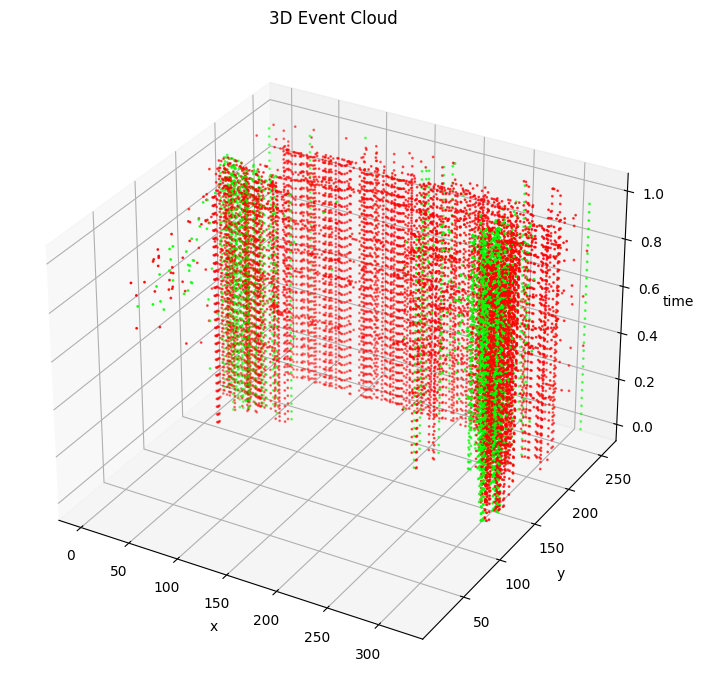

In [24]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def plot_events_3d(xs, ys, ts, polarity, max_points=50000):
    """
    Plots a 3D event cloud using (x, y, t), colored by polarity.
    """
    # Downsample if too large
    if len(ts) > max_points:
        indices = np.random.choice(len(ts), size=max_points, replace=False)
        xs, ys, ts, polarity = xs[indices], ys[indices], ts[indices], polarity[indices]

    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection='3d')

    # Normalize time
    t_min = ts.min()
    ts = ts - t_min
    ts = ts / ts.max()  # normalize to [0, 1] for color scaling

    # Choose colors
    colors = np.zeros((len(polarity), 3))
    colors[polarity == 1] = [0, 1, 0]  # ON = green
    colors[polarity == -1] = [1, 0, 0]  # OFF = red

    ax.scatter(xs, ys, ts, c=colors, s=1)

    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('time')
    ax.set_title("3D Event Cloud")

    plt.tight_layout()
    plt.show()

plot_events_3d(data["x"], data["y"], data["t"], data["p"])


In [27]:
import plotly.graph_objects as go
import numpy as np

def plot_events_plotly(xs, ys, ts, polarity, max_points=50000):
    if len(ts) > max_points:
        indices = np.random.choice(len(ts), size=max_points, replace=False)
        xs, ys, ts, polarity = xs[indices], ys[indices], ts[indices], polarity[indices]

    # Normalize time for better scaling
    ts = ts - ts.min()
    ts = ts / ts.max()

    # Color by polarity
    colors = np.where(polarity > 0, 'rgb(0,200,0)', 'rgb(200,0,0)')

    fig = go.Figure(data=[go.Scatter3d(
        x=xs, y=ys, z=ts,
        mode='markers',
        marker=dict(
            size=2,
            color=colors,
            opacity=0.7
        )
    )])

    fig.update_layout(
        scene=dict(
            xaxis_title='X',
            yaxis_title='Y',
            zaxis_title='Time'
        ),
        title="3D Event Stream",
        width=800,
        height=700
    )

    fig.show()

plot_events_plotly(data["x"], data["y"], data["t"], data["p"])


ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

In [26]:
%pip install nbformat

  Attempting uninstall: traitlets
    Found existing installation: traitlets 5.1.1
    Uninstalling traitlets-5.1.1:
      Successfully uninstalled traitlets-5.1.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [nbformat]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 8.18.1 requires prompt-toolkit<3.1.0,>=3.0.41, but you have prompt-toolkit 3.0.28 which is incompatible.
Note: you may need to restart the kernel to use updated packages.
